In [15]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report,
    mean_squared_error, r2_score, mean_absolute_error)
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("loan_dataset.csv")
print(df.shape)
df.head()

(1000, 11)


,age,income,credit_score,loan_amount,employment_years,existing_debt,dependents,education,home_owner,interest_rate,loan_approved
0,25,80800.0,719.0,12100.0,0,28400.0,2,High School,No,15.84,1
1,55,56600.0,688.0,22000.0,33,4000.0,0,Postgraduate,Yes,15.90,1
2,50,65500.0,703.0,19700.0,27,31000.0,1,High School,No,15.79,1
3,40,54000.0,734.0,19100.0,12,9100.0,4,Graduate,No,14.85,1
4,40,51900.0,623.0,19000.0,17,21600.0,1,High School,No,18.00,0


In [3]:
print(df.isna().sum())
df.describe()

age                  0
income              15
credit_score        10
loan_amount          0
employment_years     0
existing_debt        0
dependents           0
education            0
home_owner           0
interest_rate        0
loan_approved        0
dtype: int64


,age,income,credit_score,loan_amount,employment_years,existing_debt,dependents,interest_rate,loan_approved
count,1000.000000,985.000000,990.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,43.141000,54795.329949,674.072727,20401.300000,18.925000,15788.200000,1.959000,16.072150,0.620000
std,12.997463,18067.387930,70.088812,8822.103934,12.771942,10954.354323,1.412556,1.315734,0.485629
min,21.000000,15000.000000,466.000000,2000.000000,0.000000,0.000000,0.000000,12.680000,0.000000
25%,32.000000,42700.000000,628.000000,14175.000000,7.000000,6875.000000,1.000000,15.130000,0.000000
50%,43.000000,55200.000000,678.000000,20200.000000,19.000000,13700.000000,2.000000,16.060000,1.000000
75%,55.000000,66500.000000,721.000000,26700.000000,30.000000,23000.000000,3.000000,17.040000,1.000000
max,65.000000,112200.000000,850.000000,47800.000000,44.000000,56200.000000,4.000000,20.160000,1.000000


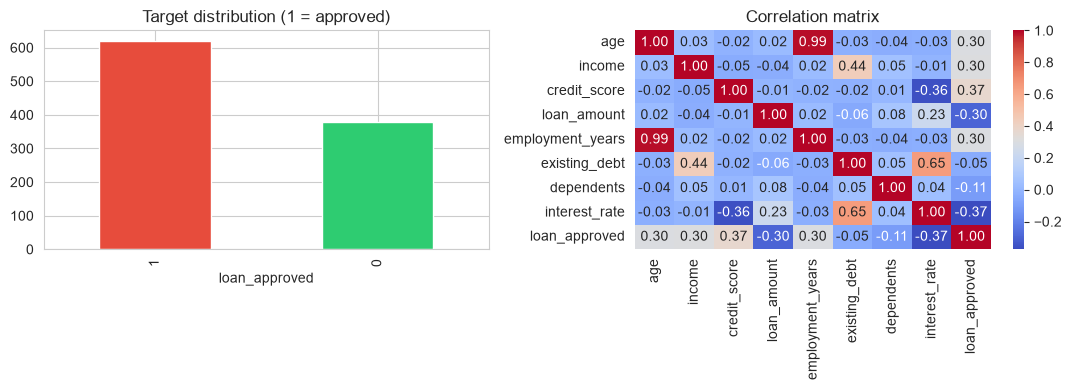

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["loan_approved"].value_counts().plot(kind="bar", ax=ax[0], color=["#e74c3c", "#2ecc71"])
ax[0].set_title("Target distribution (1 = approved)")
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

In [5]:
X = pd.get_dummies(df.drop(columns=["loan_approved", "interest_rate"]), drop_first=True)
y = df["loan_approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (800, 10) Test: (200, 10)


In [6]:
models = {
    "Logistic Regression": Pipeline([("imp", SimpleImputer(strategy="median")),
                                     ("sc", StandardScaler()),
                                     ("m", LogisticRegression(max_iter=1000))]),
    "Decision Tree": Pipeline([("imp", SimpleImputer(strategy="median")),
                               ("m", DecisionTreeClassifier(max_depth=5, random_state=42))]),
    "Random Forest": Pipeline([("imp", SimpleImputer(strategy="median")),
                               ("m", RandomForestClassifier(n_estimators=200, random_state=42))]),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name} trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained


In [7]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy").mean()
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "5-fold CV Acc": cv})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,5-fold CV Acc
Model,,,,,,
Logistic Regression,0.835,0.876,0.855,0.865,0.907,0.850
Decision Tree,0.755,0.770,0.863,0.814,0.796,0.779
Random Forest,0.775,0.806,0.839,0.822,0.840,0.818


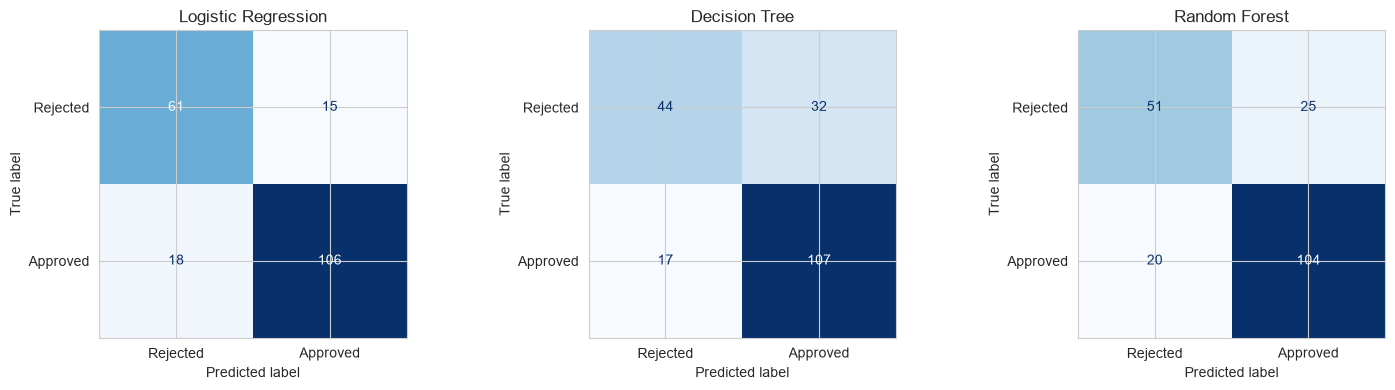

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["Rejected", "Approved"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### ROC Curves

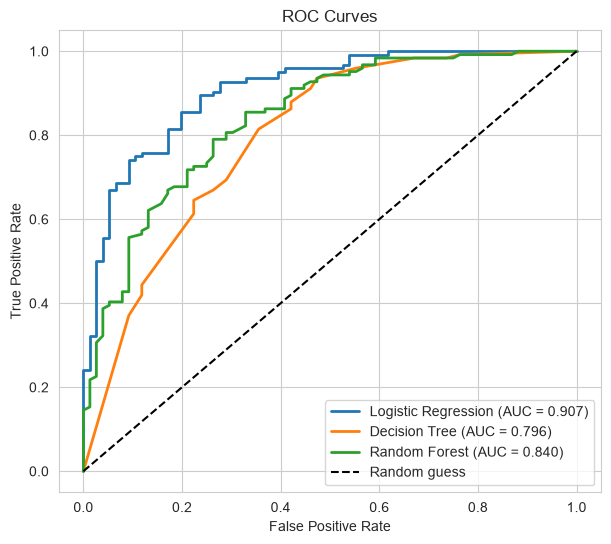

In [9]:
plt.figure(figsize=(7, 6))
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(loc="lower right"); plt.show()

In [10]:
best = results["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best)
print(classification_report(y_test, models[best].predict(X_test), target_names=["Rejected", "Approved"]))

Best model by ROC-AUC: Logistic Regression
              precision    recall  f1-score   support

    Rejected       0.77      0.80      0.79        76
    Approved       0.88      0.85      0.87       124

    accuracy                           0.83       200
   macro avg       0.82      0.83      0.83       200
weighted avg       0.84      0.83      0.84       200



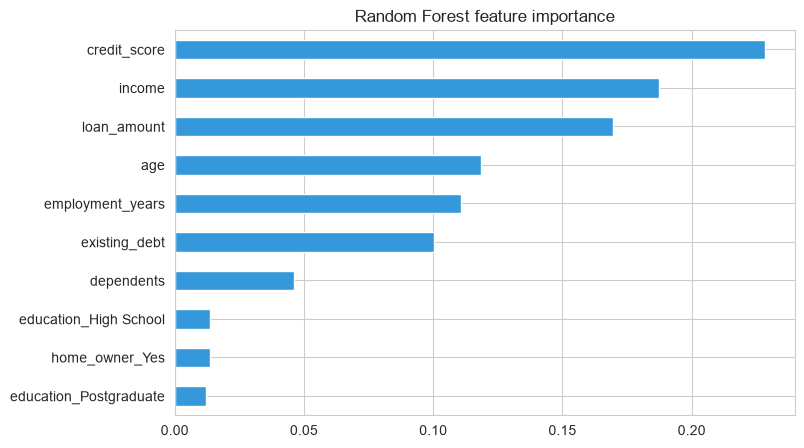

In [11]:
rf = models["Random Forest"].named_steps["m"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 5), color="#3498db", title="Random Forest feature importance")
plt.show()

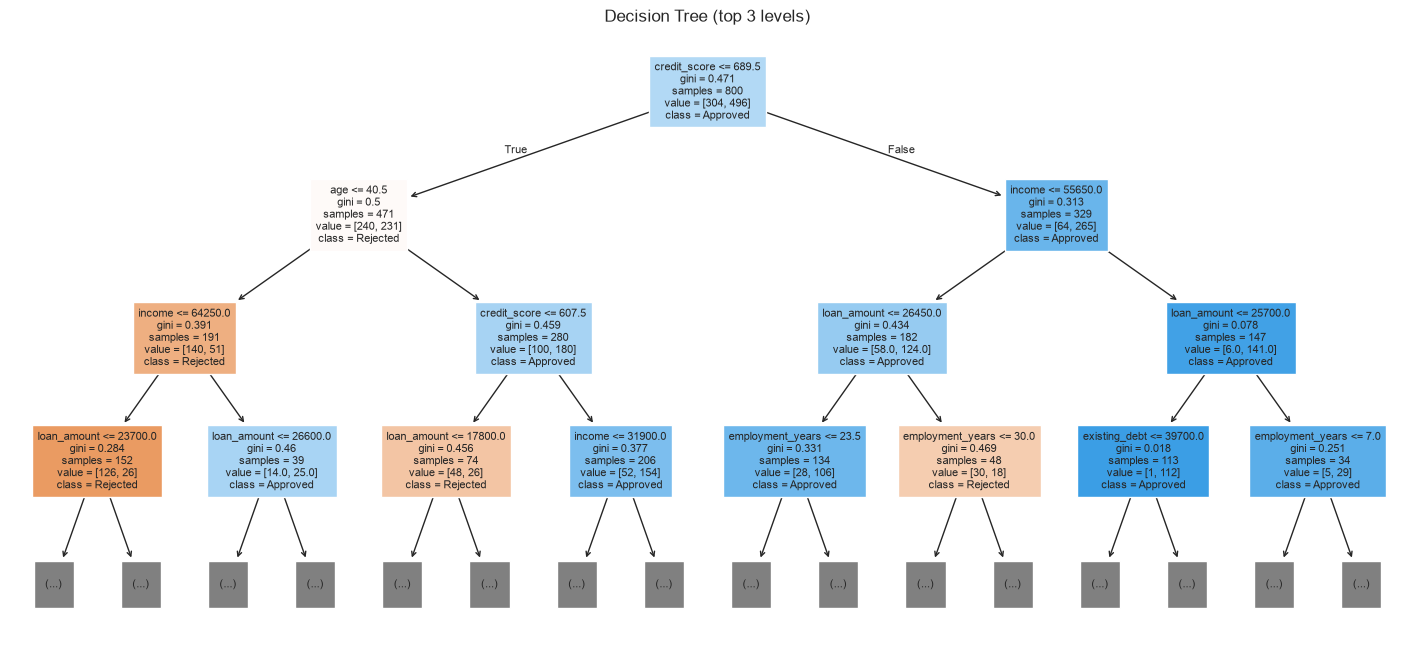

In [12]:
plt.figure(figsize=(18, 8))
plot_tree(models["Decision Tree"].named_steps["m"], feature_names=X.columns, class_names=["Rejected", "Approved"],
          filled=True, max_depth=3, fontsize=8)
plt.title("Decision Tree (top 3 levels)"); plt.show()

R²   : 0.700
RMSE : 0.704
MAE  : 0.571


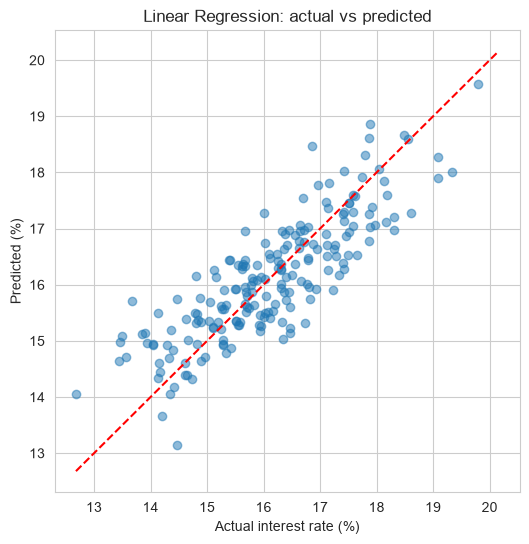

In [13]:
Xr = pd.get_dummies(df.drop(columns=["loan_approved", "interest_rate"]), drop_first=True)
yr = df["interest_rate"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)

lin = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", LinearRegression())])
lin.fit(Xr_tr, yr_tr)
pred = lin.predict(Xr_te)

print(f"R²   : {r2_score(yr_te, pred):.3f}")
print(f"RMSE : {np.sqrt(mean_squared_error(yr_te, pred)):.3f}")
print(f"MAE  : {mean_absolute_error(yr_te, pred):.3f}")

plt.figure(figsize=(6, 6))
plt.scatter(yr_te, pred, alpha=.5)
plt.plot([yr.min(), yr.max()], [yr.min(), yr.max()], "r--")
plt.xlabel("Actual interest rate (%)"); plt.ylabel("Predicted (%)"); plt.title("Linear Regression: actual vs predicted")
plt.show()

In [14]:
new = pd.DataFrame([{"age": 35, "income": 70000, "credit_score": 720, "loan_amount": 18000,
                     "employment_years": 10, "existing_debt": 8000, "dependents": 1,
                     "education_Graduate": 1, "education_Postgraduate": 0, "home_owner_Yes": 1}])
new = new.reindex(columns=X.columns, fill_value=0)
m = models[best]
print("Prediction:", "Approved" if m.predict(new)[0] == 1 else "Rejected")
print("Approval probability:", round(m.predict_proba(new)[0, 1], 3))

Prediction: Approved
Approval probability: 0.988
